# Kaggle → RetailBench: prepare, validate, and run

**Question:** Can our Kaggle demand drive RetailBench's actual inventory, ordering, pricing, and records correctly?

This is the first integration milestone. It runs two rule-based policies, not LLMs. It does not require the 29 GB historical artifacts or an API key. Results are preliminary simulation outputs, not native benchmark scores.

**VS Code:** select the project's `.venv\\Scripts\\python.exe` kernel. Run cells in order. Every full run creates a separate results session; it does not overwrite previous episodes.


In [1]:
from pathlib import Path
import sys
import json
from datetime import datetime, timezone

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'configs/kaggle_retailbench.json').is_file() and (p / 'src/data/kaggle.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook from the llm-business-shocks-sim workspace.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
if Path(sys.prefix).resolve() != (ROOT / '.venv').resolve():
    raise RuntimeError(f'Select the project .venv kernel. Current interpreter: {sys.executable}')
print('Project:', ROOT)
print('Interpreter:', sys.executable)


Project: A:\paper\llm-business-shocks-sim
Interpreter: A:\paper\llm-business-shocks-sim\.venv\Scripts\python.exe


## 1. Validate the raw data

The original CSV is preserved. Check the real schema and row coverage before choosing a series. The source is synthetic; its estimated demand is not measured customer footfall or causal evidence about pricing.


In [2]:
import pandas as pd
from IPython.display import display
from src.data.kaggle import load_sales, prepare_dataset

RAW = ROOT / 'data/raw/kaggle/sales_data.csv'
raw = load_sales(RAW)
source_metadata = json.loads((RAW.parent / 'dataset_metadata.json').read_text())
print('Dataset version:', source_metadata['version'])
print('Rows / columns:', raw.shape)
print('Store-product series:', raw.groupby(['Store ID', 'Product ID']).ngroups)
print('Date range:', raw['Date'].min().date(), 'to', raw['Date'].max().date())
print('Missing cells:', int(raw.isna().sum().sum()))
display(raw.head())


Dataset version: 8
Rows / columns: (76000, 16)
Store-product series: 100
Date range: 2022-01-01 to 2024-01-30
Missing cells: 0


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59


## 2. Prepare the adapter inputs

Split dates 60% / 20% / 20%. Select the upper-median series by training-period demand variability. The first 21 test dates form the pilot. Reference prices and averages come only from training dates. Starting inventory comes from the first episode row, once.

The adapter writes a catalog in the manifest, the demand trace, past-only history, a native calendar with null customer counts, and assumed supplier files. These are generated data, not edits to the vendor repository.


In [3]:
PREPARED = ROOT / 'data/processed/kaggle_retailbench/pilot'
manifest = prepare_dataset(RAW, PREPARED)
print('Selection:', manifest['selection'])
print('Training ends:', manifest['train_end'])
print('Validation:', manifest['validation_start'], 'to', manifest['validation_end'])
print('Episode:', manifest['test_start'], 'to', manifest['episode_end'])
print('RetailBench commit:', manifest['retailbench_commit'])
display(pd.DataFrame(manifest['catalog']).assign(store_id=manifest['store_id']))
print('\nExplicit assumptions:')
for assumption in manifest['assumptions']:
    print('•', assumption)


Selection: Upper-median training demand coefficient of variation; ties by store/product ID.
Training ends: 2023-04-01
Validation: 2023-04-02 to 2023-08-31
Episode: 2023-09-01 to 2023-09-21
RetailBench commit: f1d37b35abfa60ef5599e56d2cdbdaa4fd9b8bf3


,sku_id,category,reference_price,training_mean_demand,unit_cost,initial_inventory,max_order_quantity,store_id
0,P0006,Groceries,36.56,122.736842,21.936,421,1228,S004



Explicit assumptions:
• Synthetic estimated Demand is treated as reference-price demand, not causal ground truth.
• Only episode-start Inventory Level initializes stock; future recorded stock/sales/orders never overwrite simulated outcomes.
• Reference prices and demand means use training data only; initial inventory is observed at episode start.
• Supplier cost, lead time, holding cost and elasticity are assumptions; monetary units are unspecified.
• One assumed supplier; unlimited capacity; no reviews, returns, news, substitution, rent or spoilage.
• Daily unmet demand is observable after the day ends; future demand and shock schedules are hidden from policies.
• Calendar customer counts are null: no customer traffic is inferred or fabricated.


### What comes from data, and what is assumed?

| From Kaggle | Explicit assumptions / adaptation |
|---|---|
| Store, product, category, dates | One supplier; fixed procurement cost ratio |
| Training-period reference prices and demand averages | Two-day deliveries; five-day deliveries during a disruption |
| Episode-start inventory | Starting cash; unlimited capacity |
| Daily estimated demand | Constant-elasticity price response, with elasticity 1.5 |
| Past demand history | Unmet demand is observable after each day |

Future recorded inventory, sales, prices, and orders do **not** reset the simulation. Reviews, returns, news, spoilage, rent, and product substitution are disabled because this dataset does not support them. Read `README.md` for the upstream no-review inventory fix and valuation changes.


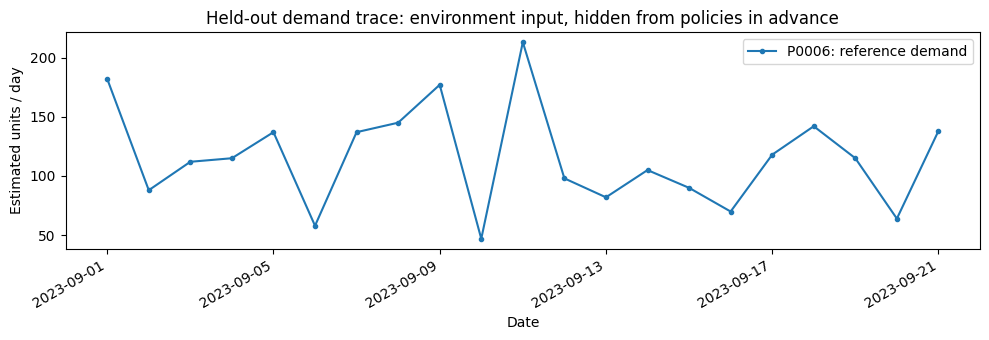

In [4]:
episode = pd.read_csv(PREPARED / 'episode.csv', parse_dates=['Date'])
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 3.5))
for sku, group in episode.groupby('Product ID'):
    ax.plot(group['Date'], group['Demand'], marker='o', markersize=3, label=f'{sku}: reference demand')
ax.set(title='Held-out demand trace: environment input, hidden from policies in advance', xlabel='Date', ylabel='Estimated units / day')
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
display(fig)
plt.close(fig)


## 3. Check the connection to real RetailBench components

The adapter inherits `RetailEnvironment`. It retains native order placement, price changes, daily processing, delivery handling, supplier lookup, records, and tool dispatch. Its SKU subclass replaces only native demand generation; the inventory subclass fixes depletion with reviews off and uses purchase-cost valuation.

The public observation contains current stock, cash, outstanding units, and past demand. It does not contain today's demand, the future trace, scenario name, or shock schedule. Requested demand becomes observable after a day ends.


In [5]:
from src.envs.kaggle_retailbench import KaggleRetailEnvironment, native

SESSION = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
RUN_ROOT = ROOT / 'results/runs/kaggle_retailbench' / SESSION
smoke = KaggleRetailEnvironment(PREPARED, RUN_ROOT / 'smoke', scenario='control')
assert isinstance(smoke, native.RetailEnvironment)
print('Native order manager:', type(smoke.order_manager).__module__)
print('Native records:', type(smoke.record_manager).__module__)
print('Database:', smoke.record_manager.db_path)
print('Available tools:', sorted(smoke.get_tools()))
initial_observation = smoke.observe()
display(pd.DataFrame(initial_observation['products']).T.drop(columns=['history']))
assert all(h['date'] < initial_observation['date'] for p in initial_observation['products'].values() for h in p['history'])
smoke.exec_tools('end_today')
first_day = pd.DataFrame(smoke.ledger)
display(first_day[['date', 'sku_id', 'opening_inventory', 'base_demand', 'demand', 'sales', 'lost_sales', 'closing_inventory']])
assert (first_day['sales'] == first_day[['opening_inventory', 'demand']].min(axis=1)).all()
assert (first_day['closing_inventory'] == first_day['opening_inventory'] - first_day['sales']).all()
print('Verified: Kaggle demand produced sales and depleted actual native inventory.')


Native order manager: module.order_manager
Native records: module.record_manager
Database: A:\paper\llm-business-shocks-sim\results\runs\kaggle_retailbench\20261017T094840160849Z\smoke\records\records.db
Available tools: ['add_note', 'end_today', 'modify_sku_price', 'place_order', 'view_business_context', 'view_current_date_supplier_prices', 'view_current_orders', 'view_funds_and_date', 'view_inventory', 'view_notes', 'view_sku_prices', 'view_sku_sales_history', 'view_supplier_price_history']


,category,inventory,on_order,price,reference_price,unit_cost,training_mean_demand,max_order_quantity
P0006,Groceries,421,0,36.56,36.56,21.936,122.736842,1228


,date,sku_id,opening_inventory,base_demand,demand,sales,lost_sales,closing_inventory
0,2023-09-01,P0006,421,182.0,182,182,0,239


Verified: Kaggle demand produced sales and depleted actual native inventory.


## 4. Run research-validity checks

These check native reuse, Kaggle demand, stock depletion, empty-stock demand, delivery timing and shocks, price response, past-only observations, deterministic reruns, cash/asset reconciliation, checksums, daily action limits, and episode boundaries.


In [6]:
import subprocess
checks = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-v'], cwd=ROOT, capture_output=True, text=True)
print(checks.stdout)
print(checks.stderr)
checks.check_returncode()



test_infinite_program_times_out (test_benchmark_launcher.FormulaWorkerTests.test_infinite_program_times_out) ... ok
test_numeric_program_and_import_restriction (test_benchmark_launcher.FormulaWorkerTests.test_numeric_program_and_import_restriction) ... ok
test_api_failure_cannot_be_silently_scored (test_benchmark_launcher.GatewayTests.test_api_failure_cannot_be_silently_scored) ... ok
test_async_gateway_for_icbe (test_benchmark_launcher.GatewayTests.test_async_gateway_for_icbe) ... ok
test_icbe_parse_failure_does_not_become_cooperation (test_benchmark_launcher.GatewayTests.test_icbe_parse_failure_does_not_become_cooperation) ... ok
test_offline_blocks_calls (test_benchmark_launcher.GatewayTests.test_offline_blocks_calls) ... ok
test_routing_caps_and_usage (test_benchmark_launcher.GatewayTests.test_routing_caps_and_usage) ... ok
test_baseline_reruns_match_and_cash_is_reconciled (test_kaggle_retailbench.IntegrationTests.test_baseline_reruns_match_and_cash_is_reconciled) ... A:\paper\llm

## 5. Run both baselines across all four scenarios

- **Fixed:** reference price; five-day training-average inventory target.
- **Adaptive:** trailing 14-day demand target; raise price below two days of coverage, lower it above seven days. Past demand is normalized to reference-price units.
- **Scenarios:** control, demand +50%, demand −30%, or delivery delay from two to five days. Shocks run on days 8–14, with recovery on days 15–21.

Both policies use the same starting state and external trace. They act through native tool dispatch. Each run stores SQLite records, tool logs, action logs, and a daily ledger. This cell executes 8 free, 21-day episodes, without API calls.


In [7]:
from src.agents.baselines import run_baseline_matrix

BASELINES = RUN_ROOT / 'baselines'
daily, summary = run_baseline_matrix(PREPARED, BASELINES)
assert len(summary) == 8 and (summary['days'] == 21).all()
assert (daily['closing_inventory'] >= 0).all()
assert (summary['net_worth_change'] - summary['contribution']).abs().max() < 1e-6
print('Results session:', RUN_ROOT)
display(summary.round(3))


Results session: A:\paper\llm-business-shocks-sim\results\runs\kaggle_retailbench\20261017T094840160849Z


,scenario,policy,days,products,contribution,revenue,fill_rate,stockout_sku_days,mean_closing_inventory,final_funds,net_worth_change
0,control,fixed,21,1,35458.469,88950.480,1.000,0,264.238,88099.097,35458.469
1,control,adaptive,21,1,35559.302,88789.616,1.000,0,267.571,89099.305,35559.302
2,demand_surge,fixed,21,1,41231.564,103318.560,0.985,2,208.095,93872.191,41231.564
3,demand_surge,adaptive,21,1,42480.124,103918.144,1.000,0,275.476,92620.048,42480.124
4,demand_decline,fixed,21,1,31653.809,79481.440,1.000,0,301.238,84294.436,31653.809
5,demand_decline,adaptive,21,1,31771.247,79320.576,1.000,0,268.524,87351.298,31771.247
6,delivery_disruption,fixed,21,1,32522.240,81528.800,0.917,2,193.810,85162.868,32522.240
7,delivery_disruption,adaptive,21,1,33048.500,81269.224,0.928,2,202.190,86588.503,33048.500


## 6. Inspect and export the results

Contribution is revenue minus cost of goods sold and holding costs, in the dataset's unspecified monetary units. It is **not** revenue or procurement cash flow. Each run verifies that contribution equals the change in cash plus inventory and in-transit assets.

Look for stockouts, delayed replenishment, excess stock after a demand decline, and differences between policies. These are baseline diagnostics, not evidence of LLM adaptation.


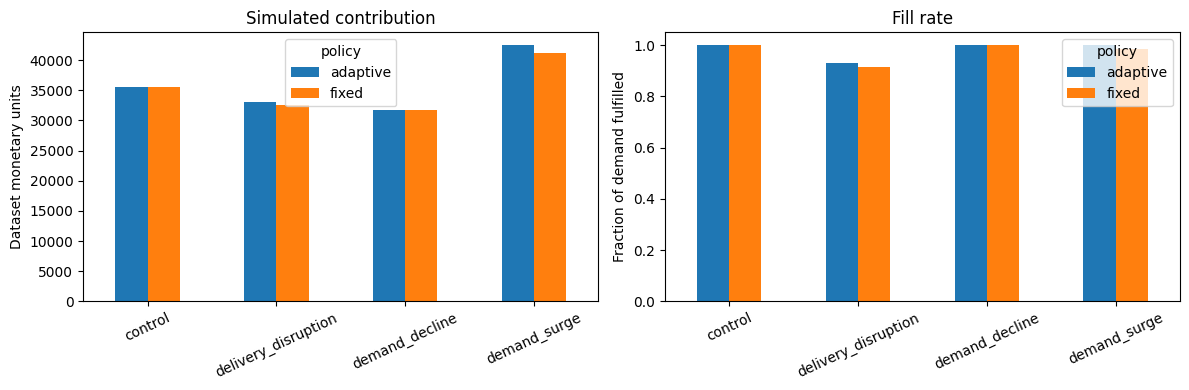

In [8]:
FIGURES = ROOT / 'results/figures'
TABLES = ROOT / 'results/tables'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, title in zip(axes, ['contribution', 'fill_rate'], ['Simulated contribution', 'Fill rate']):
    summary.pivot(index='scenario', columns='policy', values=metric).plot.bar(ax=ax, rot=25)
    ax.set(title=title, xlabel='', ylabel='Dataset monetary units' if metric == 'contribution' else 'Fraction of demand fulfilled')
    if metric == 'fill_rate':
        ax.set_ylim(0, 1.05)
fig.tight_layout()
fig.savefig(FIGURES / 'kaggle_retailbench_baselines.pdf', bbox_inches='tight')
fig.savefig(FIGURES / 'kaggle_retailbench_baselines.png', dpi=150, bbox_inches='tight')
display(fig)
plt.close(fig)
summary.to_csv(TABLES / 'kaggle_retailbench_baselines.csv', index=False)
report_table = summary[['scenario', 'policy', 'contribution', 'fill_rate', 'stockout_sku_days']]
report_table.to_latex(TABLES / 'kaggle_retailbench_baselines.tex', index=False, float_format='%.3f', escape=True)


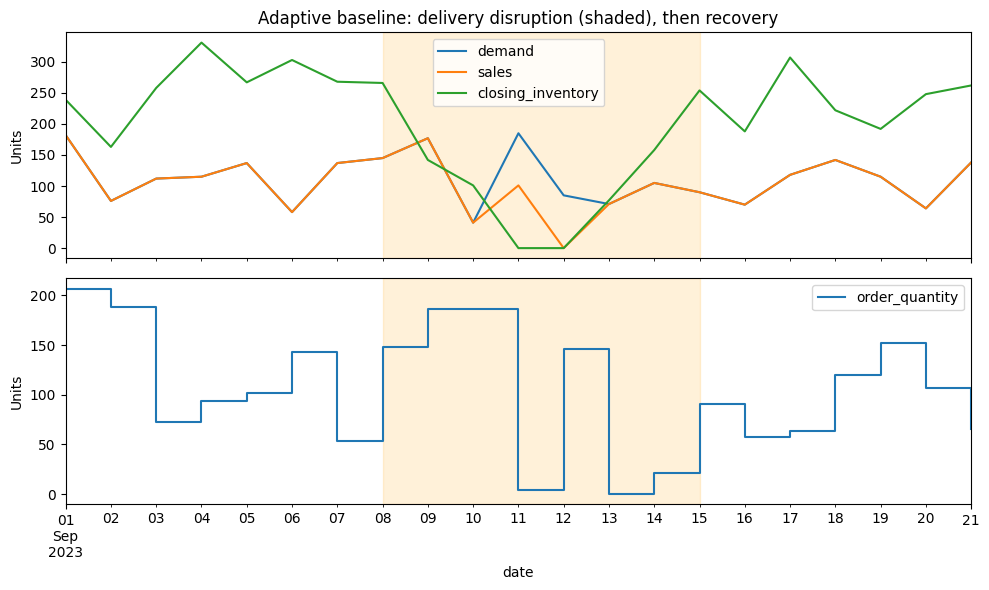

Figures: A:\paper\llm-business-shocks-sim\results\figures
Tables: A:\paper\llm-business-shocks-sim\results\tables


In [9]:
actions = pd.read_json(BASELINES / 'delivery_disruption_adaptive/actions.jsonl', lines=True)
sku = manifest['catalog'][0]['sku_id']
trace = daily.loc[(daily['scenario'] == 'delivery_disruption') & (daily['policy'] == 'adaptive')].copy()
trace['date'] = pd.to_datetime(trace['date'])
trace['order_quantity'] = [entry[sku]['order_quantity'] for entry in actions['actions']]
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
trace.plot(x='date', y=['demand', 'sales', 'closing_inventory'], ax=axes[0])
trace.plot(x='date', y='order_quantity', ax=axes[1], drawstyle='steps-post')
start = pd.Timestamp(manifest['test_start'])
for ax in axes:
    ax.axvspan(start + pd.Timedelta(days=7), start + pd.Timedelta(days=14), color='orange', alpha=0.15)
    ax.set_ylabel('Units')
axes[0].set_title('Adaptive baseline: delivery disruption (shaded), then recovery')
fig.tight_layout()
fig.savefig(FIGURES / 'kaggle_retailbench_delivery_trace.pdf', bbox_inches='tight')
fig.savefig(FIGURES / 'kaggle_retailbench_delivery_trace.png', dpi=150, bbox_inches='tight')
display(fig)
plt.close(fig)
print('Figures:', FIGURES)
print('Tables:', TABLES)


## 7. Review before adding LLMs

Write 3–5 sentences in a new Markdown cell after inspecting the outputs:

1. Did inventory and orders behave as expected during the delivery disruption?
2. Did the adaptive rule improve contribution, fill rate, both, or neither?
3. Was the apparent advantage consistent across the four scenarios?
4. Which assumptions (price response, costs, observed unmet demand) could change that conclusion?

**Next milestone:** connect an LLM policy to these same public tools and constraints, choose a provider/model and spending cap, then compare against these baselines. Broad benchmark reruns remain separate; this notebook validates our dataset integration first.

To prepare an entire store later, use `prepare_dataset(RAW, another_output_directory, store_id='S001')`. Keep that distinct from the pilot outputs. Native reset/checkpoint recovery is intentionally disabled; create a fresh environment/run directory for each episode.
